In [1]:
import sys
sys.path.append("..")

import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import mlflow
import mlflow.sklearn
from sklearn.model_selection import GroupKFold, ParameterGrid, cross_validate
from sklearn.exceptions import ConvergenceWarning
from src.data_loader import load_split, load_activity_labels
from src.model_factory import build_pipeline, RANDOM_STATE, CORR_THRESHOLD
from src.evaluation import evaluate, plot_confusion_matrix

warnings.filterwarnings("ignore", category=ConvergenceWarning)
sns.set_theme()

X_train, y_train, s_train = load_split("train")
labels = load_activity_labels()
class_names = [labels[i] for i in sorted(labels)]     # activity names in order 1..6
y0 = y_train - 1                                      # XGBoost needs classes 0..5, so every model uses the same shift
print(X_train.shape, sorted(y0.unique()))

(7352, 561) [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


In [4]:
PROJECT_ROOT = Path.cwd().parent                      # the notebook runs inside notebooks/
mlflow.set_tracking_uri(f"sqlite:///{(PROJECT_ROOT / 'mlflow.db').as_posix()}")
mlflow.set_experiment("ActivityLens-M6-tuning")
print(mlflow.get_tracking_uri())

sqlite:///c:/Users/Vaishali/activitylens/mlflow.db


In [5]:
import skops.io as sio

def log_pipeline(pipe):
    """Log a pipeline we built ourselves to MLflow. Our own classes (CorrelationFilter etc.)
    are listed as trusted, so MLflow's safe skops format accepts them."""
    trusted = sio.get_untrusted_types(data=sio.dumps(pipe))
    mlflow.sklearn.log_model(pipe, name="model", skops_trusted_types=trusted)

In [8]:
GRIDS = {
    "Logistic Regression": {"scale": [True, False], "C": [0.1, 1, 10]},
    "SVM (RBF)":           {"scale": [True, False], "C": [1, 10, 100]},
    "Random Forest":       {"scale": [False], "max_depth": [10, None], "min_samples_leaf": [1, 3]},
    "XGBoost":             {"scale": [False], "max_depth": [3, 6], "learning_rate": [0.05, 0.1]},
}

cv = GroupKFold(n_splits=5)       # groups = volunteers
rows = []

for family, grid in GRIDS.items():
    for config in ParameterGrid(grid):
        params = dict(config)
        scale = params.pop("scale")
        label = ", ".join(f"{k}={v}" for k, v in {"scaled": scale, **params}.items())

        pipe = build_pipeline(family, scale=scale, **params)
        cv_result = cross_validate(pipe, X_train, y0, groups=s_train, cv=cv,
                                   scoring=["accuracy", "f1_macro"])

        # Fit once on the full TRAINING set, only so the model can be stored with the run
        pipe.fit(X_train, y0)

        acc_mean = cv_result["test_accuracy"].mean()
        acc_std = cv_result["test_accuracy"].std()
        f1_mean = cv_result["test_f1_macro"].mean()
        fit_secs = cv_result["fit_time"].mean()

        with mlflow.start_run(run_name=f"{family} | {label}"):
            mlflow.log_params({"family": family, "scaled": scale, **params,
                               "corr_threshold": CORR_THRESHOLD,
                               "cv": "GroupKFold(n_splits=5)", "random_state": RANDOM_STATE})
            mlflow.log_metrics({"cv_accuracy_mean": acc_mean, "cv_accuracy_std": acc_std,
                                "cv_f1_macro_mean": f1_mean, "fit_seconds_per_fold": fit_secs})
            log_pipeline(pipe)

        rows.append({"family": family, "config": label, "params": {"scale": scale, **params},
                     "cv_accuracy": round(acc_mean, 4), "cv_std": round(acc_std, 4),
                     "cv_f1_macro": round(f1_mean, 4), "fit_seconds": round(fit_secs, 1)})
        print(f"{family:20s} | {label:45s} | acc {acc_mean:.4f} (std {acc_std:.4f})")

Logistic Regression  | scaled=True, C=0.1                            | acc 0.9326 (std 0.0355)
Logistic Regression  | scaled=False, C=0.1                           | acc 0.9287 (std 0.0380)
Logistic Regression  | scaled=True, C=1                              | acc 0.9310 (std 0.0331)
Logistic Regression  | scaled=False, C=1                             | acc 0.9331 (std 0.0340)
Logistic Regression  | scaled=True, C=10                             | acc 0.9248 (std 0.0323)
Logistic Regression  | scaled=False, C=10                            | acc 0.9285 (std 0.0343)
SVM (RBF)            | scaled=True, C=1                              | acc 0.9209 (std 0.0368)
SVM (RBF)            | scaled=False, C=1                             | acc 0.9315 (std 0.0360)
SVM (RBF)            | scaled=True, C=10                             | acc 0.9197 (std 0.0364)
SVM (RBF)            | scaled=False, C=10                            | acc 0.9372 (std 0.0293)
SVM (RBF)            | scaled=True, C=100         

In [6]:
from mlflow.tracking import MlflowClient

client = MlflowClient()
exp = client.get_experiment_by_name("ActivityLens-M6-tuning")
for run in client.search_runs([exp.experiment_id]):
    client.delete_run(run.info.run_id)
print("Cleaned up", exp.name)

Cleaned up ActivityLens-M6-tuning


In [7]:
mlflow.set_experiment("scratch-test")
for fam in ["Logistic Regression", "XGBoost"]:
    pipe = build_pipeline(fam, scale=False).fit(X_train.iloc[:500], y0.iloc[:500])
    with mlflow.start_run(run_name=f"test {fam}"):
        log_pipeline(pipe)
    print(fam, "logged OK")
mlflow.set_experiment("ActivityLens-M6-tuning")

2026/10/20 16:55:46 INFO mlflow.tracking.fluent: Experiment with name 'scratch-test' does not exist. Creating a new experiment.


Logistic Regression logged OK
XGBoost logged OK


<Experiment: artifact_location='file:c:/Users/Vaishali/activitylens/notebooks/mlruns/1', creation_time=1792495235975, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792495235975, lifecycle_stage='active', name='ActivityLens-M6-tuning', tags={}, trace_location=None, workspace='default'>

In [9]:
results = pd.DataFrame(rows)
table = results.drop(columns="params").sort_values(["family", "cv_accuracy"], ascending=[True, False])
print(table.to_string(index=False))
table.to_csv("../reports/m6_tuning_results.csv", index=False)

             family                                           config  cv_accuracy  cv_std  cv_f1_macro  fit_seconds
Logistic Regression                                scaled=False, C=1       0.9331  0.0340       0.9326         26.2
Logistic Regression                               scaled=True, C=0.1       0.9326  0.0355       0.9323          3.5
Logistic Regression                                 scaled=True, C=1       0.9310  0.0331       0.9307         22.1
Logistic Regression                              scaled=False, C=0.1       0.9287  0.0380       0.9284         26.5
Logistic Regression                               scaled=False, C=10       0.9285  0.0343       0.9280          1.6
Logistic Regression                                scaled=True, C=10       0.9248  0.0323       0.9244          1.4
      Random Forest scaled=False, max_depth=None, min_samples_leaf=3       0.9304  0.0405       0.9304          4.8
      Random Forest   scaled=False, max_depth=10, min_samples_leaf=3    

In [10]:
best = results.loc[results.groupby("family")["cv_accuracy"].idxmax()].set_index("family")
print(best[["config", "cv_accuracy", "cv_std", "cv_f1_macro", "fit_seconds"]].to_string())

top = best["cv_accuracy"].max()
tied = best[best["cv_accuracy"] >= top - 0.01].index.tolist()
preference = ["Logistic Regression", "SVM (RBF)", "Random Forest", "XGBoost"]
final_family = next(f for f in preference if f in tied)

print("\nBest CV accuracy:", top)
print("Tied within 0.01 of the best:", tied)
print("SELECTED FINAL MODEL FAMILY:", final_family)

                                                               config  cv_accuracy  cv_std  cv_f1_macro  fit_seconds
family                                                                                                              
Logistic Regression                                 scaled=False, C=1       0.9331  0.0340       0.9326         26.2
Random Forest        scaled=False, max_depth=None, min_samples_leaf=3       0.9304  0.0405       0.9304          4.8
SVM (RBF)                                          scaled=False, C=10       0.9372  0.0293       0.9370          1.0
XGBoost                  scaled=False, learning_rate=0.1, max_depth=3       0.9332  0.0388       0.9339          8.8

Best CV accuracy: 0.9372
Tied within 0.01 of the best: ['Logistic Regression', 'Random Forest', 'SVM (RBF)', 'XGBoost']
SELECTED FINAL MODEL FAMILY: Logistic Regression


In [11]:
X_test, y_test, s_test = load_split("test")
y_test0 = y_test - 1
class_ids0 = list(range(6))

def rebuild(family):
    params = dict(best.loc[family, "params"])
    scale = params.pop("scale")
    return build_pipeline(family, scale=scale, **params)

mlflow.set_experiment("ActivityLens-M6-final-eval")
fitted, test_rows = {}, []
for family in best.index:
    pipe = rebuild(family).fit(X_train, y0)
    accuracy, per_class, cm, y_pred = evaluate(pipe, X_test, y_test0, class_ids0, class_names)
    macro_f1 = per_class["f1"].mean()
    fitted[family] = (pipe, accuracy, per_class, cm)
    test_rows.append({"family": family, "cv_accuracy": best.loc[family, "cv_accuracy"],
                      "test_accuracy": round(accuracy, 4), "test_macro_f1": round(macro_f1, 4)})

    with mlflow.start_run(run_name=f"FINALIST {family}"):
        mlflow.set_tag("selected", str(family == final_family))
        mlflow.log_params({"family": family, **{k: str(v) for k, v in best.loc[family, "params"].items()}})
        mlflow.log_metrics({"cv_accuracy_mean": float(best.loc[family, "cv_accuracy"]),
                            "test_accuracy": float(accuracy), "test_macro_f1": float(macro_f1)})
        log_pipeline(pipe)

print(pd.DataFrame(test_rows).to_string(index=False))

2026/10/20 17:26:38 INFO mlflow.tracking.fluent: Experiment with name 'ActivityLens-M6-final-eval' does not exist. Creating a new experiment.


             family  cv_accuracy  test_accuracy  test_macro_f1
Logistic Regression       0.9331         0.9481         0.9482
      Random Forest       0.9304         0.9413         0.9397
          SVM (RBF)       0.9372         0.9532         0.9525
            XGBoost       0.9332         0.9549         0.9547


Logistic Regression | test accuracy: 0.9481
                    precision  recall     f1  support
WALKING                 0.952   0.994  0.972      496
WALKING_UPSTAIRS        0.955   0.945  0.950      471
WALKING_DOWNSTAIRS      0.978   0.943  0.960      420
SITTING                 0.936   0.870  0.902      491
STANDING                0.881   0.945  0.912      532
LAYING                  0.998   0.987  0.993      537


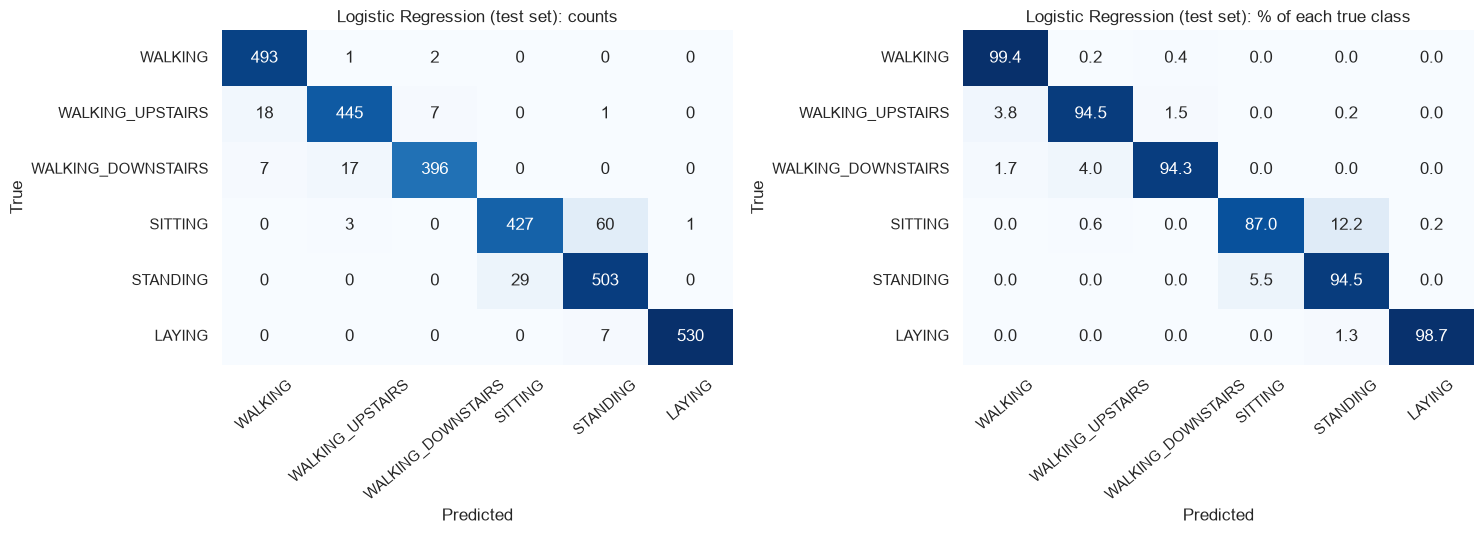

SITTING -> STANDING: 60 of 491
STANDING -> SITTING: 29 of 532


In [12]:
final_pipe, final_acc, final_per_class, final_cm = fitted[final_family]
joblib.dump(final_pipe, "../models/final_model.joblib")

print(final_family, "| test accuracy:", round(final_acc, 4))
print(final_per_class)
plot_confusion_matrix(final_cm, class_names, f"{final_family} (test set)",
                      "../reports/figures/cm_final.png")

i_sit, i_std = class_names.index("SITTING"), class_names.index("STANDING")
print("SITTING -> STANDING:", final_cm[i_sit, i_std], "of", final_cm[i_sit].sum())
print("STANDING -> SITTING:", final_cm[i_std, i_sit], "of", final_cm[i_std].sum())